SCRIPT_PATH: /Users/silvia/Sciebo/01_Projects/01_Huberfeld_MEA_GG_DK/+Projects-Huberfeld/02_mouse_tissue/GG/+Analysis/analysis_quantification_inter_pre_ictal
DATA_DIR   : /Users/silvia/Sciebo/01_Projects/01_Huberfeld_MEA_GG_DK/+Projects-Huberfeld/02_mouse_tissue/GG/+Analysis/analysis_quantification_inter_pre_ictal/data_iid
STAIN_DIR  : /Users/silvia/Sciebo/01_Projects/01_Huberfeld_MEA_GG_DK/+Projects-Huberfeld/02_mouse_tissue/GG/+Analysis/analysis_quantification_inter_pre_ictal/data_staining
PLOTS_DIR  : /Users/silvia/Sciebo/01_Projects/01_Huberfeld_MEA_GG_DK/+Projects-Huberfeld/02_mouse_tissue/GG/+Analysis/analysis_quantification_inter_pre_ictal/plots/IID

PROCESSING GROUP: p5

--- Processing p5_slice1 ---
Spike file:   /Users/silvia/Sciebo/01_Projects/01_Huberfeld_MEA_GG_DK/+Projects-Huberfeld/02_mouse_tissue/GG/+Analysis/analysis_quantification_inter_pre_ictal/data_iid/tumor_p5/gg1-4_s3.csv
Stain1 file (mCherry-IUE): /Users/silvia/Sciebo/01_Projects/01_Huberfeld_MEA_GG_DK/+Projects-

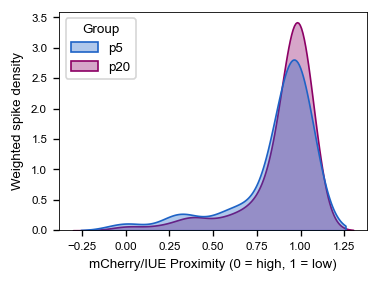

✅ Saved: /Users/silvia/Sciebo/01_Projects/01_Huberfeld_MEA_GG_DK/+Projects-Huberfeld/02_mouse_tissue/GG/+Analysis/analysis_quantification_inter_pre_ictal/plots/IID/A2_stackedKDE_mCherry.pdf


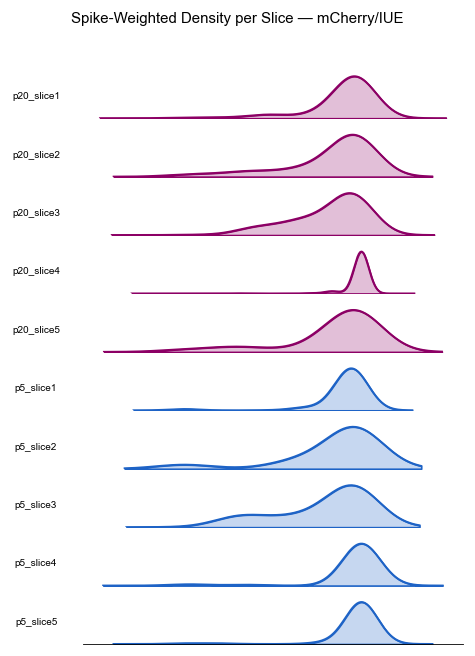

✅ Saved: /Users/silvia/Sciebo/01_Projects/01_Huberfeld_MEA_GG_DK/+Projects-Huberfeld/02_mouse_tissue/GG/+Analysis/analysis_quantification_inter_pre_ictal/plots/IID/B1_weightedKDE_GFAP.pdf


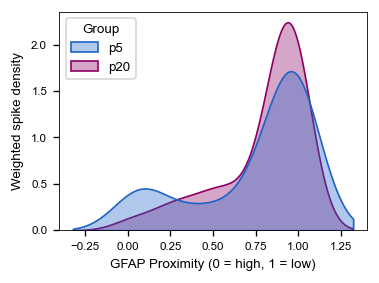

✅ Saved: /Users/silvia/Sciebo/01_Projects/01_Huberfeld_MEA_GG_DK/+Projects-Huberfeld/02_mouse_tissue/GG/+Analysis/analysis_quantification_inter_pre_ictal/plots/IID/B2_stackedKDE_GFAP.pdf


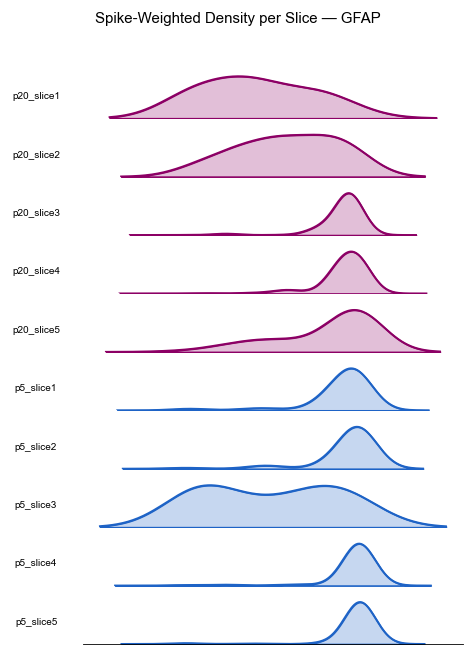


✅ All plots saved to: /Users/silvia/Sciebo/01_Projects/01_Huberfeld_MEA_GG_DK/+Projects-Huberfeld/02_mouse_tissue/GG/+Analysis/analysis_quantification_inter_pre_ictal/plots/IID


In [ ]:
# IID 
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, mannwhitneyu
# ============================================================
# BASE PATHS (Notebook-based, no __file__)
# ============================================================
SCRIPT_PATH = Path().resolve()               # notebook working directory
DATA_DIR  = SCRIPT_PATH / "data_iid"         # spike / IID csvs
STAIN_DIR = SCRIPT_PATH / "data_staining"    # staining csvs
PLOTS_DIR = SCRIPT_PATH / "plots/IID"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

print("SCRIPT_PATH:", SCRIPT_PATH)
print("DATA_DIR   :", DATA_DIR)
print("STAIN_DIR  :", STAIN_DIR)
print("PLOTS_DIR  :", PLOTS_DIR)

# Group subfolders
DATA_DIR_P5  = DATA_DIR / "tumor_p5"
DATA_DIR_P20 = DATA_DIR / "tumor_p20"

STAIN_DIR_P5  = STAIN_DIR / "tumor_p5"
STAIN_DIR_P20 = STAIN_DIR / "tumor_p20"


# ======================================================================
# 1) SAVE-FIGURES HELPERS (PDF)
# ======================================================================
def save_current_fig(name: str):
    out = PLOTS_DIR / f"{name}.pdf"
    fig = plt.gcf()
    fig.canvas.draw_idle()
    fig.savefig(out, format="pdf", bbox_inches="tight")
    print(f"✅ Saved: {out}")


# ======================================================================
# 2) Helper: unify electrode column naming
# ======================================================================
def fix_electrode_column(df):
    df.columns = df.columns.str.strip()
    lower = [c.lower() for c in df.columns]
    possible = ["electrode", "channel", "chan", "electrodes"]

    if "Electrode" in df.columns:
        return df

    for i, c in enumerate(lower):
        if c in possible:
            return df.rename(columns={df.columns[i]: "Electrode"})

    raise KeyError("No Electrode column found in file: columns = " + str(df.columns))


# ======================================================================
# 3) DEFINE DATASET (p5 + p20) with TWO stainings
# stain1 = mCherry-IUE (tumor marker)
# stain2 = GFAP
# ======================================================================

groups = {
    "p5": {
        "slices": [
            {
                "spike":  DATA_DIR_P5 / "gg1-4_s3.csv",
                "stain1": STAIN_DIR_P5 / "gg1-4_s3_mCherry.csv",
                "stain2": STAIN_DIR_P5 / "gg1-4_s3_gfap.csv",
                "time":   (100, 600),
            },
            {
                "spike":  DATA_DIR_P5 / "gg1-5_s1.csv",
                "stain1": STAIN_DIR_P5 / "gg1-5_s1_mCherry.csv",
                "stain2": STAIN_DIR_P5 / "gg1-5_s1_gfap.csv",
                "time":   (100, 600),
            },
            {
                "spike":  DATA_DIR_P5 / "gg2-2_s1.csv",
                "stain1": STAIN_DIR_P5 / "gg2-2_s1_mCherry.csv",
                "stain2": STAIN_DIR_P5 / "gg2-2_s1_gfap.csv",
                "time":   (100, 600),
            },
            {
                "spike":  DATA_DIR_P5 / "gg4-2_s1.csv",
                "stain1": STAIN_DIR_P5 / "gg4-2_s1_mCherry.csv",
                "stain2": STAIN_DIR_P5 / "gg4-2_s1_gfap.csv",
                "time":   (100, 600),
            },
            {
                "spike":  DATA_DIR_P5 / "gg4-3_s1.csv",
                "stain1": STAIN_DIR_P5 / "gg4-3_s1_mCherry.csv",
                "stain2": STAIN_DIR_P5 / "gg4-3_s1_gfap.csv",
                "time":   (100, 600),
            },
        ]
    },

    "p20": {
        "slices": [
            {
                "spike":  DATA_DIR_P20 / "gg2-5_s1.csv",
                "stain1": STAIN_DIR_P20 / "gg2-5_s1_mCherry.csv",
                "stain2": STAIN_DIR_P20 / "gg2-5_s1_gfap.csv",
                "time":   (100, 600),
            },
            {
                "spike":  DATA_DIR_P20 / "gg2-6_s1.csv",
                "stain1": STAIN_DIR_P20 / "gg2-6_s1_mCherry.csv",
                "stain2": STAIN_DIR_P20 / "gg2-6_s1_gfap.csv",
                "time":   (100, 600),
            },
            {
                "spike":  DATA_DIR_P20 / "gg2-6_s2.csv",
                "stain1": STAIN_DIR_P20 / "gg2-6_s2_mCherry.csv",
                "stain2": STAIN_DIR_P20 / "gg2-6_s2_gfap.csv",
                "time":   (100, 600),
            },
            {
                "spike":  DATA_DIR_P20 / "gg4-5_s1.csv",
                "stain1": STAIN_DIR_P20 / "gg4-5_s1_mCherry.csv",
                "stain2": STAIN_DIR_P20 / "gg4-5_s1_gfap.csv",
                "time":   (100, 600),
            },
            {
                "spike":  DATA_DIR_P20 / "gg4-5_s2.csv",
                "stain1": STAIN_DIR_P20 / "gg4-5_s2_mCherry.csv",
                "stain2": STAIN_DIR_P20 / "gg4-5_s2_gfap.csv",
                "time":   (100, 600),
            },
        ]
    }
}

# ======================================================================
# 4) PROCESS ALL GROUPS + SLICES
# ======================================================================
all_results = []
group_rhos_tumor = {}
group_rhos_gfap  = {}

for group_name, group_data in groups.items():

    print(f"\n==============================================")
    print(f"PROCESSING GROUP: {group_name}")
    print("==============================================")

    group_rhos_tumor[group_name] = []
    group_rhos_gfap[group_name]  = []

    for idx, entry in enumerate(group_data["slices"]):

        spike_file  = Path(entry["spike"])
        stain1_file = Path(entry["stain1"])  # mCherry-IUE
        stain2_file = Path(entry["stain2"])  # GFAP
        time_win    = entry["time"]

        slice_name = f"{group_name}_slice{idx+1}"

        print(f"\n--- Processing {slice_name} ---")
        print(f"Spike file:   {spike_file}")
        print(f"Stain1 file (mCherry-IUE): {stain1_file}")
        print(f"Stain2 file (GFAP):        {stain2_file}")
        print(f"Requested time window:     {time_win}")

        # ------------------------------
        # LOAD SPIKES
        # ------------------------------
        df_sp = pd.read_csv(spike_file)
        df_sp = fix_electrode_column(df_sp)
        df_sp["Electrode"] = df_sp["Electrode"].astype(str)

        # ------------------------------
        # APPLY TIME WINDOW (with warnings)
        # ------------------------------
        if time_win is not None:
            if "Time" not in df_sp.columns:
                print(f"  ⚠ WARNING: Time column NOT found. Cannot apply {time_win}. Using full duration.")
            else:
                tmin, tmax = time_win
                before = len(df_sp)
                df_sp = df_sp[(df_sp["Time"] >= tmin) & (df_sp["Time"] <= tmax)]
                after = len(df_sp)

                if after == 0:
                    print(f"  ⚠ WARNING: No spikes found in time window {tmin}-{tmax}s. Slice will have zero spike counts.")
                else:
                    print(f"  Applied time window: {tmin}-{tmax}s  → kept {after}/{before} spikes")
        else:
            print("  Using full duration (no time window).")

        # ------------------------------
        # Spike counts per electrode
        # ------------------------------
        spike_counts = df_sp.groupby("Electrode").size().reset_index(name="Spikes")
        valid_electrodes = spike_counts["Electrode"].unique()

        # ------------------------------
        # LOAD STAIN1 (mCherry-IUE)
        # ------------------------------
        df_st1 = pd.read_csv(stain1_file)
        df_st1 = fix_electrode_column(df_st1)
        df_st1["Electrode"] = df_st1["Electrode"].astype(str)
        df_st1 = df_st1[df_st1["Electrode"].isin(valid_electrodes)]

        renamed1 = False
        for cand in ["value", "Value", "Intensity", "intensity"]:
            if cand in df_st1.columns:
                df_st1 = df_st1.rename(columns={cand: "StainingTumor"})
                renamed1 = True
                break
        if not renamed1 and "StainingTumor" not in df_st1.columns:
            raise KeyError(f"No staining column found for stain1 (mCherry) in {stain1_file}")

        # ------------------------------
        # LOAD STAIN2 (GFAP)
        # ------------------------------
        df_st2 = pd.read_csv(stain2_file)
        df_st2 = fix_electrode_column(df_st2)
        df_st2["Electrode"] = df_st2["Electrode"].astype(str)
        df_st2 = df_st2[df_st2["Electrode"].isin(valid_electrodes)]

        renamed2 = False
        for cand in ["value", "Value", "Intensity", "intensity"]:
            if cand in df_st2.columns:
                df_st2 = df_st2.rename(columns={cand: "StainingGFAP"})
                renamed2 = True
                break
        if not renamed2 and "StainingGFAP" not in df_st2.columns:
            raise KeyError(f"No staining column found for stain2 (GFAP) in {stain2_file}")

        # ------------------------------
        # MERGE ONLY ELECTRODES PRESENT IN BOTH STAININGS AND SPIKES
        # ------------------------------
        df_st = pd.merge(
            df_st1[["Electrode", "StainingTumor"]],
            df_st2[["Electrode", "StainingGFAP"]],
            on="Electrode",
            how="inner"
        )

        # ------------------------------
        # NORMALIZE BOTH STAININGS
        # ------------------------------
        min_tumor = df_st["StainingTumor"].min()
        max_tumor = df_st["StainingTumor"].max()
        df_st["StainingTumorNorm"] = (df_st["StainingTumor"] - min_tumor) / (max_tumor - min_tumor + 1e-9)
        df_st["TumorProximity"] = 1 - df_st["StainingTumorNorm"]

        min_gfap = df_st["StainingGFAP"].min()
        max_gfap = df_st["StainingGFAP"].max()
        df_st["GFAPNorm"] = (df_st["StainingGFAP"] - min_gfap) / (max_gfap - min_gfap + 1e-9)
        df_st["GFAPProximity"] = 1 - df_st["GFAPNorm"]

        # ------------------------------
        # MERGE WITH SPIKE COUNTS
        # ------------------------------
        df_merged = pd.merge(df_st, spike_counts, on="Electrode", how="inner")

        # Drop missing proximity rows just in case
        df_merged = df_merged.dropna(subset=["TumorProximity", "GFAPProximity"])

        # Z-score normalization of spikes
        mean_sp = df_merged["Spikes"].mean()
        std_sp = df_merged["Spikes"].std()
        df_merged["SpikesZ"] = 0 if (std_sp == 0 or np.isnan(std_sp)) else (df_merged["Spikes"] - mean_sp) / std_sp

        df_merged["Group"] = group_name
        df_merged["Slice"] = slice_name

        all_results.append(df_merged)

        # ------------------------------
        # SPEARMAN CORRELATIONS
        # ------------------------------
        rho_tumor, p_tumor = spearmanr(df_merged["TumorProximity"], df_merged["Spikes"])
        group_rhos_tumor[group_name].append(rho_tumor)

        rho_gfap, p_gfap = spearmanr(df_merged["GFAPProximity"], df_merged["Spikes"])
        group_rhos_gfap[group_name].append(rho_gfap)

        print(f"  Spearman vs mCherry TumorProximity: rho = {rho_tumor:.3f}, p = {p_tumor:.4f}")
        print(f"  Spearman vs GFAP Proximity:         rho = {rho_gfap:.3f}, p = {p_gfap:.4f}")


# Combine all slices
df_all = pd.concat(all_results, ignore_index=True)



# ======================================================================
# 5) SLICE-LEVEL SUMMARY (for boxplots)
# ======================================================================
slice_stats = (
    df_all
    .groupby(["Group", "Slice"])
    .agg({"TumorProximity": "median",
          "GFAPProximity": "median"})
    .reset_index()
)


# ======================================================================
# 6) GROUP COMPARISONS (p5 vs p20) FOR BOTH CORRELATIONS
# ======================================================================
if len(group_rhos_tumor.get("p20", [])) > 0:
    stat_tumor, p_group_tumor = mannwhitneyu(
        group_rhos_tumor["p5"], group_rhos_tumor["p20"], alternative="two-sided"
    )
    print("\nMann–Whitney (p5 vs p20) for mCherry TumorProximity rho:")
    print(f"  U = {stat_tumor:.3f}, p = {p_group_tumor:.4f}")
else:
    print("\n⚠ p20 contains no slices → cannot compare mCherry TumorProximity correlations yet.")

if len(group_rhos_gfap.get("p20", [])) > 0:
    stat_gfap, p_group_gfap = mannwhitneyu(
        group_rhos_gfap["p5"], group_rhos_gfap["p20"], alternative="two-sided"
    )
    print("\nMann–Whitney (p5 vs p20) for GFAP Proximity rho:")
    print(f"  U = {stat_gfap:.3f}, p = {p_group_gfap:.4f}")
else:
    print("\n⚠ p20 contains no slices → cannot compare GFAP proximity correlations yet.")


# ======================================================================
# 7) DEBUG CHECK (optional)
# ======================================================================
print("\n\n==================== DEBUG CHECK ====================\n")

def debug_slice(df_slice, label, proximity_col):
    print(f"\n--- DEBUG for {label} ---")
    print(f"  NaN in {proximity_col}: {df_slice[proximity_col].isna().sum()}")
    print(f"  NaN in Spikes:          {df_slice['Spikes'].isna().sum()}")
    print(f"  Inf in {proximity_col}: {np.isinf(df_slice[proximity_col]).sum()}")
    print(f"  Inf in Spikes:          {np.isinf(df_slice['Spikes']).sum()}")
    uniq = df_slice[proximity_col].nunique()
    print(f"  Unique values in {proximity_col}: {uniq}")
    if uniq < 2:
        print("  ❌ KDE will fail: proximity has < 2 unique values")
    if df_slice["Spikes"].sum() == 0:
        print("  ⚠ WARNING: This slice has ZERO spikes")
    print(f"  Total rows: {len(df_slice)}")
    if len(df_slice) < 3:
        print("  ❌ KDE may fail: too few data points (<3)")

for sl in df_all["Slice"].unique():
    sub = df_all[df_all["Slice"] == sl]
    print(f"\n================ SLICE: {sl} ================")
    debug_slice(sub, f"{sl} (mCherry TumorProximity)", "TumorProximity")
    debug_slice(sub, f"{sl} (GFAPProximity)", "GFAPProximity")


# ============================================================
# SAVE PER-SLICE CORRELATION RESULTS
# ============================================================

slice_corr_rows = []

for group_name in groups.keys():
    for i, rho in enumerate(group_rhos_tumor.get(group_name, [])):
        slice_corr_rows.append({
            "Group": group_name,
            "Slice": f"{group_name}_slice{i+1}",
            "Marker": "mCherry",
            "Spearman_rho": rho
        })

    for i, rho in enumerate(group_rhos_gfap.get(group_name, [])):
        slice_corr_rows.append({
            "Group": group_name,
            "Slice": f"{group_name}_slice{i+1}",
            "Marker": "GFAP",
            "Spearman_rho": rho
        })

df_slice_corr = pd.DataFrame(slice_corr_rows)

slice_corr_path = PLOTS_DIR / "slice_level_correlations.csv"
df_slice_corr.to_csv(slice_corr_path, index=False)
print("✅ Saved:", slice_corr_path)

# ============================================================
# SAVE GROUP-LEVEL TESTS
# ============================================================

group_test_rows = []

if len(group_rhos_tumor.get("p20", [])) > 0:
    stat_tumor, p_group_tumor = mannwhitneyu(
        group_rhos_tumor["p5"],
        group_rhos_tumor["p20"],
        alternative="two-sided"
    )

    group_test_rows.append({
        "Marker": "mCherry",
        "Test": "Mann-Whitney",
        "U_stat": stat_tumor,
        "p_value": p_group_tumor
    })

if len(group_rhos_gfap.get("p20", [])) > 0:
    stat_gfap, p_group_gfap = mannwhitneyu(
        group_rhos_gfap["p5"],
        group_rhos_gfap["p20"],
        alternative="two-sided"
    )

    group_test_rows.append({
        "Marker": "GFAP",
        "Test": "Mann-Whitney",
        "U_stat": stat_gfap,
        "p_value": p_group_gfap
    })

df_group_tests = pd.DataFrame(group_test_rows)

group_test_path = PLOTS_DIR / "group_level_comparisons.csv"
df_group_tests.to_csv(group_test_path, index=False)
print("✅ Saved:", group_test_path)

# ======================================================================
# 8) GLOBAL PUBLICATION STYLE
# ======================================================================
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['axes.linewidth'] = 0.5
mpl.rcParams['font.size'] = 8
mpl.rcParams['xtick.labelsize'] = 7
mpl.rcParams['ytick.labelsize'] = 7
mpl.rcParams['axes.labelsize'] = 8
mpl.rcParams['figure.titlesize'] = 9
mpl.rcParams['lines.linewidth'] = 1.0
mpl.rcParams['savefig.dpi'] = 300
mpl.rcParams['figure.dpi'] = 120

COLOR_MAP = {"p5": "#1E63C6", "p20": "#8c0065"}

df_all["mCherryProx"] = df_all["TumorProximity"]
df_all["GFAPProx"]    = df_all["GFAPProximity"]

import matplotlib.pyplot as plt
import seaborn as sns


# ============================================================
# GENERIC KDE FUNCTIONS
# ============================================================

def plot_weighted_kde(df, xcol, weight_col, group_col,
                      palette, xlabel, ylabel, out_stem):
    """Weighted KDE (group-level)."""
    plt.figure(figsize=(3.2, 2.4))

    sns.kdeplot(
        data=df,
        x=xcol,
        weights=df[weight_col],
        hue=group_col,
        palette=palette,
        fill=True,
        alpha=0.35,
        common_norm=False
    )

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.tight_layout()
    save_current_fig(out_stem)
    plt.show()
    plt.close()


def plot_stacked_kde_per_slice(df, xcol, weight_col,
                               slice_col, group_col, palette,
                               xlabel, suptitle, out_pdf):
    """Flow-cytometry style stacked KDE per slice."""

    slice_order = sorted(df[slice_col].unique())

    fig, axes = plt.subplots(
        len(slice_order), 1,
        figsize=(4, 0.55 * len(slice_order)),
        sharex=True
    )

    if len(slice_order) == 1:
        axes = [axes]

    for i, sl in enumerate(slice_order):

        sub = df[df[slice_col] == sl]
        grp = str(sub[group_col].iloc[0])
        col = palette.get(grp, "gray")
        ax = axes[i]

        sns.kdeplot(
            data=sub,
            x=xcol,
            weights=sub[weight_col],
            color=col,
            fill=True,
            alpha=0.25,
            linewidth=1.0,
            ax=ax
        )

        sns.kdeplot(
            data=sub,
            x=xcol,
            weights=sub[weight_col],
            color=col,
            linewidth=1.2,
            ax=ax
        )

        ax.set_yticks([])
        ax.set_ylabel(str(sl), rotation=0,
                      labelpad=28, fontsize=6, va="center")

        for side in ["top", "right", "left"]:
            ax.spines[side].set_visible(False)

        if i < len(slice_order) - 1:
            ax.spines["bottom"].set_visible(False)
            ax.set_xticks([])
        else:
            ax.set_xlabel(xlabel)

    fig.suptitle(suptitle, fontsize=9)
    fig.tight_layout(rect=[0, 0, 1, 0.95])

    fig.savefig(out_pdf, format="pdf", bbox_inches="tight")
    print(f"✅ Saved: {out_pdf}")

    plt.show()
    plt.close(fig)


# ============================================================
# RUN — mCherry/IUE
# ============================================================

plot_weighted_kde(
    df=df_all,
    xcol="mCherryProx",
    weight_col="Spikes",
    group_col="Group",
    palette=COLOR_MAP,
    xlabel="mCherry/IUE Proximity (0 = high, 1 = low)",
    ylabel="Weighted spike density",
    out_stem="A1_weightedKDE_mCherry"
)

plot_stacked_kde_per_slice(
    df=df_all,
    xcol="mCherryProx",
    weight_col="Spikes",
    slice_col="Slice",
    group_col="Group",
    palette=COLOR_MAP,
    xlabel="mCherry/IUE Proximity (0 = high, 1 = low)",
    suptitle="Spike-Weighted Density per Slice — mCherry/IUE",
    out_pdf=PLOTS_DIR / "A2_stackedKDE_mCherry.pdf"
)


# ============================================================
# RUN — GFAP
# ============================================================

plot_weighted_kde(
    df=df_all,
    xcol="GFAPProx",
    weight_col="Spikes",
    group_col="Group",
    palette=COLOR_MAP,
    xlabel="GFAP Proximity (0 = high, 1 = low)",
    ylabel="Weighted spike density",
    out_stem="B1_weightedKDE_GFAP"
)

plot_stacked_kde_per_slice(
    df=df_all,
    xcol="GFAPProx",
    weight_col="Spikes",
    slice_col="Slice",
    group_col="Group",
    palette=COLOR_MAP,
    xlabel="GFAP Proximity (0 = high, 1 = low)",
    suptitle="Spike-Weighted Density per Slice — GFAP",
    out_pdf=PLOTS_DIR / "B2_stackedKDE_GFAP.pdf"
)




print("\n✅ All plots saved to:", PLOTS_DIR)

SCRIPT_PATH: /Users/silvia/Sciebo/01_Projects/01_Huberfeld_MEA_GG_DK/+Projects-Huberfeld/02_mouse_tissue/GG/+Analysis/analysis_quantification_inter_pre_ictal
DATA_DIR   : /Users/silvia/Sciebo/01_Projects/01_Huberfeld_MEA_GG_DK/+Projects-Huberfeld/02_mouse_tissue/GG/+Analysis/analysis_quantification_inter_pre_ictal/data_pid_id
STAIN_DIR  : /Users/silvia/Sciebo/01_Projects/01_Huberfeld_MEA_GG_DK/+Projects-Huberfeld/02_mouse_tissue/GG/+Analysis/analysis_quantification_inter_pre_ictal/data_staining
PLOTS_DIR  : /Users/silvia/Sciebo/01_Projects/01_Huberfeld_MEA_GG_DK/+Projects-Huberfeld/02_mouse_tissue/GG/+Analysis/analysis_quantification_inter_pre_ictal/plots/PID

PROCESSING GROUP: p5

--- Processing p5_slice1 ---
Spike file:   /Users/silvia/Sciebo/01_Projects/01_Huberfeld_MEA_GG_DK/+Projects-Huberfeld/02_mouse_tissue/GG/+Analysis/analysis_quantification_inter_pre_ictal/data_pid_id/tumor_p5/gg1-4_s3.csv
Stain1 file (mCherry-IUE): /Users/silvia/Sciebo/01_Projects/01_Huberfeld_MEA_GG_DK/+Pro

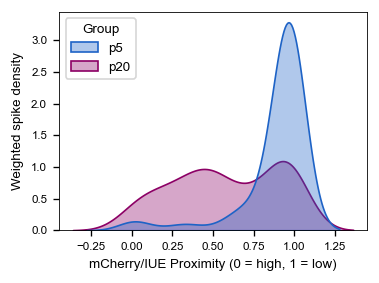

✅ Saved: /Users/silvia/Sciebo/01_Projects/01_Huberfeld_MEA_GG_DK/+Projects-Huberfeld/02_mouse_tissue/GG/+Analysis/analysis_quantification_inter_pre_ictal/plots/PID/A2_stackedKDE_mCherry.pdf


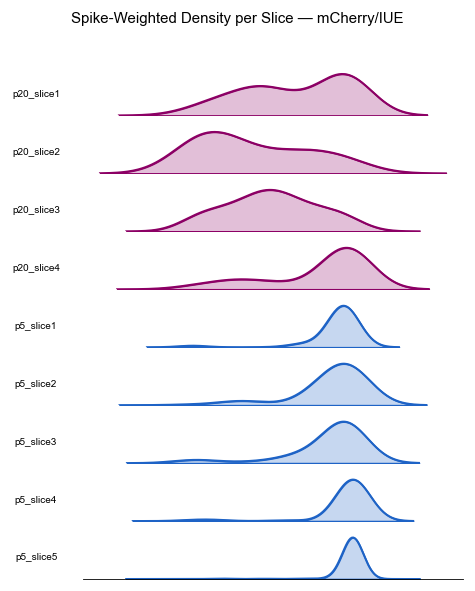

✅ Saved: /Users/silvia/Sciebo/01_Projects/01_Huberfeld_MEA_GG_DK/+Projects-Huberfeld/02_mouse_tissue/GG/+Analysis/analysis_quantification_inter_pre_ictal/plots/PID/B1_weightedKDE_GFAP.pdf


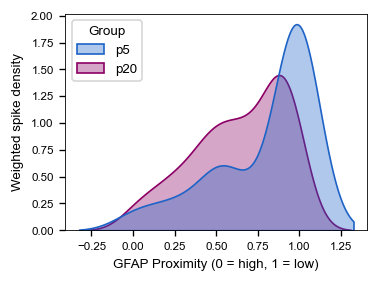

✅ Saved: /Users/silvia/Sciebo/01_Projects/01_Huberfeld_MEA_GG_DK/+Projects-Huberfeld/02_mouse_tissue/GG/+Analysis/analysis_quantification_inter_pre_ictal/plots/PID/B2_stackedKDE_GFAP.pdf


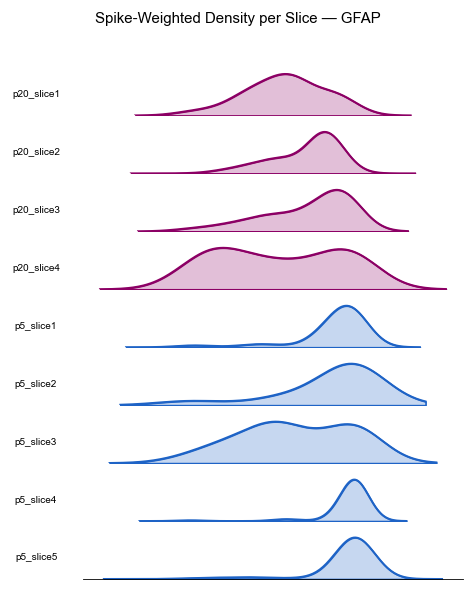


✅ All plots saved to: /Users/silvia/Sciebo/01_Projects/01_Huberfeld_MEA_GG_DK/+Projects-Huberfeld/02_mouse_tissue/GG/+Analysis/analysis_quantification_inter_pre_ictal/plots/PID


In [ ]:
#PID

from pathlib import Path
import matplotlib.pyplot as plt

# ============================================================
# BASE PATHS (Notebook-based, no __file__)
# ============================================================
SCRIPT_PATH = Path().resolve()               # notebook working directory
DATA_DIR  = SCRIPT_PATH / "data_pid_id"         # spike / IID csvs
STAIN_DIR = SCRIPT_PATH / "data_staining"    # staining csvs
PLOTS_DIR = SCRIPT_PATH / "plots/PID"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

print("SCRIPT_PATH:", SCRIPT_PATH)
print("DATA_DIR   :", DATA_DIR)
print("STAIN_DIR  :", STAIN_DIR)
print("PLOTS_DIR  :", PLOTS_DIR)

# Group subfolders
DATA_DIR_P5  = DATA_DIR / "tumor_p5"
DATA_DIR_P20 = DATA_DIR / "tumor_p20"

STAIN_DIR_P5  = STAIN_DIR / "tumor_p5"
STAIN_DIR_P20 = STAIN_DIR / "tumor_p20"


# ======================================================================
# 1) SAVE-FIGURES HELPERS (PDF)
# ======================================================================
def save_current_fig(name: str):
    out = PLOTS_DIR / f"{name}.pdf"
    fig = plt.gcf()
    fig.canvas.draw_idle()
    fig.savefig(out, format="pdf", bbox_inches="tight")
    print(f"✅ Saved: {out}")


# ======================================================================
# 2) Helper: unify electrode column naming
# ======================================================================
def fix_electrode_column(df):
    df.columns = df.columns.str.strip()
    lower = [c.lower() for c in df.columns]
    possible = ["electrode", "channel", "chan", "electrodes"]

    if "Electrode" in df.columns:
        return df

    for i, c in enumerate(lower):
        if c in possible:
            return df.rename(columns={df.columns[i]: "Electrode"})

    raise KeyError("No Electrode column found in file: columns = " + str(df.columns))


# ======================================================================
# 3) DEFINE DATASET (p5 + p20) with TWO stainings
# stain1 = mCherry-IUE (tumor marker)
# stain2 = GFAP
# ======================================================================

groups = {
    "p5": {
        "slices": [
            {
                "spike":  DATA_DIR_P5 / "gg1-4_s3.csv",
                "stain1": STAIN_DIR_P5 / "gg1-4_s3_mCherry.csv",
                "stain2": STAIN_DIR_P5 / "gg1-4_s3_gfap.csv",
                "time":   (700, 900),
            },
            {
                "spike":  DATA_DIR_P5 / "gg1-4_s4.csv",
                "stain1": STAIN_DIR_P5 / "gg1-4_s4_mCherry.csv",
                "stain2": STAIN_DIR_P5 / "gg1-4_s4_gfap.csv",
                "time":   (600, 740),
            },
            {
                "spike":  DATA_DIR_P5 / "gg1-5_s1.csv",
                "stain1": STAIN_DIR_P5 / "gg1-5_s1_mCherry.csv",
                "stain2": STAIN_DIR_P5 / "gg1-5_s1_gfap.csv",
                "time":   (700, 900),
            },
            # (you commented this out originally; keep it out unless you have the spike file)
            #{
            #    "spike":  DATA_DIR_P5 / "gg2-2_s1.csv",
            #    "stain1": STAIN_DIR_P5 / "gg2-2_s1_mCherry.csv",
            #    "stain2": STAIN_DIR_P5 / "gg2-2_s1_gfap.csv",
            #    "time":   (600, 720),
            #},
            {
                "spike":  DATA_DIR_P5 / "gg4-2_s1.csv",
                "stain1": STAIN_DIR_P5 / "gg4-2_s1_mCherry.csv",
                "stain2": STAIN_DIR_P5 / "gg4-2_s1_gfap.csv",
                "time":   (900, 1000),
            },
            {
                # you had "GG4-3_s1.csv" with caps; adapt to standard naming:
                # If your actual file is capitalized, change back.
                "spike":  DATA_DIR_P5 / "gg4-3_s1.csv",
                "stain1": STAIN_DIR_P5 / "gg4-3_s1_mCherry.csv",
                "stain2": STAIN_DIR_P5 / "gg4-3_s1_gfap.csv",
                "time":   (1700, 1955),
            },
        ]
    },

    "p20": {
        "slices": [
            {
                "spike":  DATA_DIR_P20 / "gg2-5_s1.csv",
                "stain1": STAIN_DIR_P20 / "gg2-5_s1_mCherry.csv",
                "stain2": STAIN_DIR_P20 / "gg2-5_s1_gfap.csv",
                "time":   (1500, 2500),
            },
            {
                "spike":  DATA_DIR_P20 / "gg2-6_s1.csv",
                "stain1": STAIN_DIR_P20 / "gg2-6_s1_mCherry.csv",
                "stain2": STAIN_DIR_P20 / "gg2-6_s1_gfap.csv",
                "time":   (1000, 1600),
            },
            {
                # ⚠ You had "gg2-6_2.csv" (missing _s2). In your earlier code it was gg2-6_s2.csv.
                # Pick the real filename you have on disk.
                "spike":  DATA_DIR_P20 / "gg2-6_s2.csv",
                "stain1": STAIN_DIR_P20 / "gg2-6_s2_mCherry.csv",
                "stain2": STAIN_DIR_P20 / "gg2-6_s2_gfap.csv",
                "time":   (1300, 1750),
            },
            {
                "spike":  DATA_DIR_P20 / "gg2-5_s2.csv",
                "stain1": STAIN_DIR_P20 / "gg2-5_s2_mCherry.csv",
                "stain2": STAIN_DIR_P20 / "gg2-5_s2_gfap.csv",
                "time":   (1400, 1600),
            },
        ]
    }
}

# ======================================================================
# 4) PROCESS ALL GROUPS + SLICES
# ======================================================================
all_results = []
group_rhos_tumor = {}
group_rhos_gfap  = {}

for group_name, group_data in groups.items():

    print(f"\n==============================================")
    print(f"PROCESSING GROUP: {group_name}")
    print("==============================================")

    group_rhos_tumor[group_name] = []
    group_rhos_gfap[group_name]  = []

    for idx, entry in enumerate(group_data["slices"]):

        spike_file  = Path(entry["spike"])
        stain1_file = Path(entry["stain1"])  # mCherry-IUE
        stain2_file = Path(entry["stain2"])  # GFAP
        time_win    = entry["time"]

        slice_name = f"{group_name}_slice{idx+1}"

        print(f"\n--- Processing {slice_name} ---")
        print(f"Spike file:   {spike_file}")
        print(f"Stain1 file (mCherry-IUE): {stain1_file}")
        print(f"Stain2 file (GFAP):        {stain2_file}")
        print(f"Requested time window:     {time_win}")

        # ------------------------------
        # LOAD SPIKES
        # ------------------------------
        df_sp = pd.read_csv(spike_file)
        df_sp = fix_electrode_column(df_sp)
        df_sp["Electrode"] = df_sp["Electrode"].astype(str)

        # ------------------------------
        # APPLY TIME WINDOW (with warnings)
        # ------------------------------
        if time_win is not None:
            if "Time" not in df_sp.columns:
                print(f"  ⚠ WARNING: Time column NOT found. Cannot apply {time_win}. Using full duration.")
            else:
                tmin, tmax = time_win
                before = len(df_sp)
                df_sp = df_sp[(df_sp["Time"] >= tmin) & (df_sp["Time"] <= tmax)]
                after = len(df_sp)

                if after == 0:
                    print(f"  ⚠ WARNING: No spikes found in time window {tmin}-{tmax}s. Slice will have zero spike counts.")
                else:
                    print(f"  Applied time window: {tmin}-{tmax}s  → kept {after}/{before} spikes")
        else:
            print("  Using full duration (no time window).")

        # ------------------------------
        # Spike counts per electrode
        # ------------------------------
        spike_counts = df_sp.groupby("Electrode").size().reset_index(name="Spikes")
        valid_electrodes = spike_counts["Electrode"].unique()

        # ------------------------------
        # LOAD STAIN1 (mCherry-IUE)
        # ------------------------------
        df_st1 = pd.read_csv(stain1_file)
        df_st1 = fix_electrode_column(df_st1)
        df_st1["Electrode"] = df_st1["Electrode"].astype(str)
        df_st1 = df_st1[df_st1["Electrode"].isin(valid_electrodes)]

        renamed1 = False
        for cand in ["value", "Value", "Intensity", "intensity"]:
            if cand in df_st1.columns:
                df_st1 = df_st1.rename(columns={cand: "StainingTumor"})
                renamed1 = True
                break
        if not renamed1 and "StainingTumor" not in df_st1.columns:
            raise KeyError(f"No staining column found for stain1 (mCherry) in {stain1_file}")

        # ------------------------------
        # LOAD STAIN2 (GFAP)
        # ------------------------------
        df_st2 = pd.read_csv(stain2_file)
        df_st2 = fix_electrode_column(df_st2)
        df_st2["Electrode"] = df_st2["Electrode"].astype(str)
        df_st2 = df_st2[df_st2["Electrode"].isin(valid_electrodes)]

        renamed2 = False
        for cand in ["value", "Value", "Intensity", "intensity"]:
            if cand in df_st2.columns:
                df_st2 = df_st2.rename(columns={cand: "StainingGFAP"})
                renamed2 = True
                break
        if not renamed2 and "StainingGFAP" not in df_st2.columns:
            raise KeyError(f"No staining column found for stain2 (GFAP) in {stain2_file}")

        # ------------------------------
        # MERGE ONLY ELECTRODES PRESENT IN BOTH STAININGS AND SPIKES
        # ------------------------------
        df_st = pd.merge(
            df_st1[["Electrode", "StainingTumor"]],
            df_st2[["Electrode", "StainingGFAP"]],
            on="Electrode",
            how="inner"
        )

        # ------------------------------
        # NORMALIZE BOTH STAININGS
        # ------------------------------
        min_tumor = df_st["StainingTumor"].min()
        max_tumor = df_st["StainingTumor"].max()
        df_st["StainingTumorNorm"] = (df_st["StainingTumor"] - min_tumor) / (max_tumor - min_tumor + 1e-9)
        df_st["TumorProximity"] = 1 - df_st["StainingTumorNorm"]

        min_gfap = df_st["StainingGFAP"].min()
        max_gfap = df_st["StainingGFAP"].max()
        df_st["GFAPNorm"] = (df_st["StainingGFAP"] - min_gfap) / (max_gfap - min_gfap + 1e-9)
        df_st["GFAPProximity"] = 1 - df_st["GFAPNorm"]

        # ------------------------------
        # MERGE WITH SPIKE COUNTS
        # ------------------------------
        df_merged = pd.merge(df_st, spike_counts, on="Electrode", how="inner")

        # Drop missing proximity rows just in case
        df_merged = df_merged.dropna(subset=["TumorProximity", "GFAPProximity"])

        # Z-score normalization of spikes
        mean_sp = df_merged["Spikes"].mean()
        std_sp = df_merged["Spikes"].std()
        df_merged["SpikesZ"] = 0 if (std_sp == 0 or np.isnan(std_sp)) else (df_merged["Spikes"] - mean_sp) / std_sp

        df_merged["Group"] = group_name
        df_merged["Slice"] = slice_name

        all_results.append(df_merged)

        # ------------------------------
        # SPEARMAN CORRELATIONS
        # ------------------------------
        rho_tumor, p_tumor = spearmanr(df_merged["TumorProximity"], df_merged["Spikes"])
        group_rhos_tumor[group_name].append(rho_tumor)

        rho_gfap, p_gfap = spearmanr(df_merged["GFAPProximity"], df_merged["Spikes"])
        group_rhos_gfap[group_name].append(rho_gfap)

        print(f"  Spearman vs mCherry TumorProximity: rho = {rho_tumor:.3f}, p = {p_tumor:.4f}")
        print(f"  Spearman vs GFAP Proximity:         rho = {rho_gfap:.3f}, p = {p_gfap:.4f}")


# Combine all slices
df_all = pd.concat(all_results, ignore_index=True)



# ======================================================================
# 5) SLICE-LEVEL SUMMARY (for boxplots)
# ======================================================================
slice_stats = (
    df_all
    .groupby(["Group", "Slice"])
    .agg({"TumorProximity": "median",
          "GFAPProximity": "median"})
    .reset_index()
)


# ======================================================================
# 6) GROUP COMPARISONS (p5 vs p20) FOR BOTH CORRELATIONS
# ======================================================================
if len(group_rhos_tumor.get("p20", [])) > 0:
    stat_tumor, p_group_tumor = mannwhitneyu(
        group_rhos_tumor["p5"], group_rhos_tumor["p20"], alternative="two-sided"
    )
    print("\nMann–Whitney (p5 vs p20) for mCherry TumorProximity rho:")
    print(f"  U = {stat_tumor:.3f}, p = {p_group_tumor:.4f}")
else:
    print("\n⚠ p20 contains no slices → cannot compare mCherry TumorProximity correlations yet.")

if len(group_rhos_gfap.get("p20", [])) > 0:
    stat_gfap, p_group_gfap = mannwhitneyu(
        group_rhos_gfap["p5"], group_rhos_gfap["p20"], alternative="two-sided"
    )
    print("\nMann–Whitney (p5 vs p20) for GFAP Proximity rho:")
    print(f"  U = {stat_gfap:.3f}, p = {p_group_gfap:.4f}")
else:
    print("\n⚠ p20 contains no slices → cannot compare GFAP proximity correlations yet.")


# ======================================================================
# 7) DEBUG CHECK (optional)
# ======================================================================
print("\n\n==================== DEBUG CHECK ====================\n")

def debug_slice(df_slice, label, proximity_col):
    print(f"\n--- DEBUG for {label} ---")
    print(f"  NaN in {proximity_col}: {df_slice[proximity_col].isna().sum()}")
    print(f"  NaN in Spikes:          {df_slice['Spikes'].isna().sum()}")
    print(f"  Inf in {proximity_col}: {np.isinf(df_slice[proximity_col]).sum()}")
    print(f"  Inf in Spikes:          {np.isinf(df_slice['Spikes']).sum()}")
    uniq = df_slice[proximity_col].nunique()
    print(f"  Unique values in {proximity_col}: {uniq}")
    if uniq < 2:
        print("  ❌ KDE will fail: proximity has < 2 unique values")
    if df_slice["Spikes"].sum() == 0:
        print("  ⚠ WARNING: This slice has ZERO spikes")
    print(f"  Total rows: {len(df_slice)}")
    if len(df_slice) < 3:
        print("  ❌ KDE may fail: too few data points (<3)")

for sl in df_all["Slice"].unique():
    sub = df_all[df_all["Slice"] == sl]
    print(f"\n================ SLICE: {sl} ================")
    debug_slice(sub, f"{sl} (mCherry TumorProximity)", "TumorProximity")
    debug_slice(sub, f"{sl} (GFAPProximity)", "GFAPProximity")


# ============================================================
# SAVE PER-SLICE CORRELATION RESULTS
# ============================================================

slice_corr_rows = []

for group_name in groups.keys():
    for i, rho in enumerate(group_rhos_tumor.get(group_name, [])):
        slice_corr_rows.append({
            "Group": group_name,
            "Slice": f"{group_name}_slice{i+1}",
            "Marker": "mCherry",
            "Spearman_rho": rho
        })

    for i, rho in enumerate(group_rhos_gfap.get(group_name, [])):
        slice_corr_rows.append({
            "Group": group_name,
            "Slice": f"{group_name}_slice{i+1}",
            "Marker": "GFAP",
            "Spearman_rho": rho
        })

df_slice_corr = pd.DataFrame(slice_corr_rows)

slice_corr_path = PLOTS_DIR / "slice_level_correlations.csv"
df_slice_corr.to_csv(slice_corr_path, index=False)
print("✅ Saved:", slice_corr_path)

# ============================================================
# SAVE GROUP-LEVEL TESTS
# ============================================================

group_test_rows = []

if len(group_rhos_tumor.get("p20", [])) > 0:
    stat_tumor, p_group_tumor = mannwhitneyu(
        group_rhos_tumor["p5"],
        group_rhos_tumor["p20"],
        alternative="two-sided"
    )

    group_test_rows.append({
        "Marker": "mCherry",
        "Test": "Mann-Whitney",
        "U_stat": stat_tumor,
        "p_value": p_group_tumor
    })

if len(group_rhos_gfap.get("p20", [])) > 0:
    stat_gfap, p_group_gfap = mannwhitneyu(
        group_rhos_gfap["p5"],
        group_rhos_gfap["p20"],
        alternative="two-sided"
    )

    group_test_rows.append({
        "Marker": "GFAP",
        "Test": "Mann-Whitney",
        "U_stat": stat_gfap,
        "p_value": p_group_gfap
    })

df_group_tests = pd.DataFrame(group_test_rows)

group_test_path = PLOTS_DIR / "group_level_comparisons.csv"
df_group_tests.to_csv(group_test_path, index=False)
print("✅ Saved:", group_test_path)

# ======================================================================
# 8) GLOBAL PUBLICATION STYLE
# ======================================================================
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['axes.linewidth'] = 0.5
mpl.rcParams['font.size'] = 8
mpl.rcParams['xtick.labelsize'] = 7
mpl.rcParams['ytick.labelsize'] = 7
mpl.rcParams['axes.labelsize'] = 8
mpl.rcParams['figure.titlesize'] = 9
mpl.rcParams['lines.linewidth'] = 1.0
mpl.rcParams['savefig.dpi'] = 300
mpl.rcParams['figure.dpi'] = 120

COLOR_MAP = {"p5": "#1E63C6", "p20": "#8c0065"}

df_all["mCherryProx"] = df_all["TumorProximity"]
df_all["GFAPProx"]    = df_all["GFAPProximity"]

import matplotlib.pyplot as plt
import seaborn as sns


# ============================================================
# GENERIC KDE FUNCTIONS
# ============================================================

def plot_weighted_kde(df, xcol, weight_col, group_col,
                      palette, xlabel, ylabel, out_stem):
    """Weighted KDE (group-level)."""
    plt.figure(figsize=(3.2, 2.4))

    sns.kdeplot(
        data=df,
        x=xcol,
        weights=df[weight_col],
        hue=group_col,
        palette=palette,
        fill=True,
        alpha=0.35,
        common_norm=False
    )

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.tight_layout()
    save_current_fig(out_stem)
    plt.show()
    plt.close()


def plot_stacked_kde_per_slice(df, xcol, weight_col,
                               slice_col, group_col, palette,
                               xlabel, suptitle, out_pdf):
    """Flow-cytometry style stacked KDE per slice."""

    slice_order = sorted(df[slice_col].unique())

    fig, axes = plt.subplots(
        len(slice_order), 1,
        figsize=(4, 0.55 * len(slice_order)),
        sharex=True
    )

    if len(slice_order) == 1:
        axes = [axes]

    for i, sl in enumerate(slice_order):

        sub = df[df[slice_col] == sl]
        grp = str(sub[group_col].iloc[0])
        col = palette.get(grp, "gray")
        ax = axes[i]

        sns.kdeplot(
            data=sub,
            x=xcol,
            weights=sub[weight_col],
            color=col,
            fill=True,
            alpha=0.25,
            linewidth=1.0,
            ax=ax
        )

        sns.kdeplot(
            data=sub,
            x=xcol,
            weights=sub[weight_col],
            color=col,
            linewidth=1.2,
            ax=ax
        )

        ax.set_yticks([])
        ax.set_ylabel(str(sl), rotation=0,
                      labelpad=28, fontsize=6, va="center")

        for side in ["top", "right", "left"]:
            ax.spines[side].set_visible(False)

        if i < len(slice_order) - 1:
            ax.spines["bottom"].set_visible(False)
            ax.set_xticks([])
        else:
            ax.set_xlabel(xlabel)

    fig.suptitle(suptitle, fontsize=9)
    fig.tight_layout(rect=[0, 0, 1, 0.95])

    fig.savefig(out_pdf, format="pdf", bbox_inches="tight")
    print(f"✅ Saved: {out_pdf}")

    plt.show()
    plt.close(fig)


# ============================================================
# RUN — mCherry/IUE
# ============================================================

plot_weighted_kde(
    df=df_all,
    xcol="mCherryProx",
    weight_col="Spikes",
    group_col="Group",
    palette=COLOR_MAP,
    xlabel="mCherry/IUE Proximity (0 = high, 1 = low)",
    ylabel="Weighted spike density",
    out_stem="A1_weightedKDE_mCherry"
)

plot_stacked_kde_per_slice(
    df=df_all,
    xcol="mCherryProx",
    weight_col="Spikes",
    slice_col="Slice",
    group_col="Group",
    palette=COLOR_MAP,
    xlabel="mCherry/IUE Proximity (0 = high, 1 = low)",
    suptitle="Spike-Weighted Density per Slice — mCherry/IUE",
    out_pdf=PLOTS_DIR / "A2_stackedKDE_mCherry.pdf"
)


# ============================================================
# RUN — GFAP
# ============================================================

plot_weighted_kde(
    df=df_all,
    xcol="GFAPProx",
    weight_col="Spikes",
    group_col="Group",
    palette=COLOR_MAP,
    xlabel="GFAP Proximity (0 = high, 1 = low)",
    ylabel="Weighted spike density",
    out_stem="B1_weightedKDE_GFAP"
)

plot_stacked_kde_per_slice(
    df=df_all,
    xcol="GFAPProx",
    weight_col="Spikes",
    slice_col="Slice",
    group_col="Group",
    palette=COLOR_MAP,
    xlabel="GFAP Proximity (0 = high, 1 = low)",
    suptitle="Spike-Weighted Density per Slice — GFAP",
    out_pdf=PLOTS_DIR / "B2_stackedKDE_GFAP.pdf"
)




print("\n✅ All plots saved to:", PLOTS_DIR)